# 20 · ReturnWise model export

## Purpose

Export the selected real model, calibration map, feature schema, dataset fingerprint, and one-time internal holdout metrics for application inference.

## Method

Serialize only the model selected by training CV and calibrated using its separate calibration split, and only when the internal holdout exceeds the random/prevalence discrimination baseline and the constant-prevalence Brier/log-loss baselines. Store the temporal scenario, selected calibrator, validation metrics, available permutation importance, and editable decision defaults. Reload the artifact and require prediction consistency before marking export complete.

## Interpretation

Use the displayed tables, figures, and saved metrics produced by this run. Do not fill this section with assumed outcomes. For every result, distinguish observed evidence from interpretation.

## Limitations

The exported artifact is only valid for the saved feature schema and installed package versions. Re-run experiments after data or dependency changes.

## References

Model export and prediction schema: returnwise.export and returnwise.storage.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'returnwise').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display
from returnwise.research_state import load_state, save_state
state = load_state()
print('Project:', ROOT)
print('Notebook:', '20 · ReturnWise model export')


Project: C:\Users\Lenovo\Documents\Who is back
Notebook: 20 · ReturnWise model export


Exported artifact metadata:


application_version                                                      0.1.0
selected_model               Soft voting: HistGradientBoosting + Logistic r...
feature_columns              [customer_age, product_price, discount_percent...
prediction_scenario                                               pre_shipment
selected_calibrator                                                       beta
dataset_fingerprint          2ae5e87906198d2e3688c12bd807b33194115aea579aac...
validation_metrics           {'roc_auc': 0.5894811010085066, 'pr_auc': 0.55...
decision_configuration       {'review_capacity_percent': [5, 10, 20, 30], '...
exported_at                                          2026-11-15T07:25:48+00:00
probability_is_calibrated                                                 True
dtype: object

Saved artifact reload and prediction consistency checks passed on the held-out rows; these predictions are not substituted for the measured evaluation.


Competition submission file created from unlabeled test rows: C:\Users\Lenovo\Documents\Who is back\data\kaggle\returnwise_submission.csv
Submission schema matches sample_submission.csv: True


,ID,returned
0,38683,0.460344
1,64939,0.462570
2,3954,0.497191
3,120374,0.574215
4,172861,0.466542


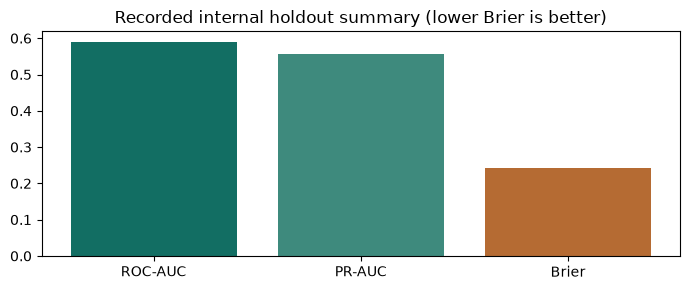

In [2]:
from returnwise.data.kaggle import read_metadata
from returnwise.export import export_model, make_competition_submission, predict_with_artifact
from returnwise.paths import KAGGLE_DIR
from returnwise.research_state import load_state, save_state
from returnwise.storage import load_model_artifact
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

state = load_state()
if 'final_model' not in state or 'final_metrics' not in state:
    raise RuntimeError('Run notebook 19 to complete the one-time final holdout evaluation.')
manifest = state.get('dataset_manifest') or {}
kaggle_metadata = read_metadata()
fingerprint = (kaggle_metadata or {}).get('fingerprint_sha256')
if not fingerprint:
    from returnwise.storage import active_dataset_fingerprint
    fingerprint = active_dataset_fingerprint()
importance = state.get('permutation_importance', [])
metadata = export_model(
    model=state['final_model'],
    feature_columns=state['feature_columns'],
    selected_model=state['selected_model'],
    dataset_fingerprint=fingerprint,
    calibrators=state['final_calibrators'],
    selected_calibrator=state['selected_calibrator'],
    permutation_importance=importance,
    prediction_scenario='pre_shipment',
    validation_metrics=state['final_metrics'],
    decision_configuration={
        'review_capacity_percent': [5, 10, 20, 30],
        'default_capacity_percent': 10,
        'fixed_threshold': 0.5,
        'uncertainty_confidence_ceiling': 0.60,
        'cost_scenarios': state.get('cost_scenarios', {}),
        'costs_are_simulated': True,
    },
)
print('Exported artifact metadata:')
display(pd.Series(metadata))
raw, calibrated = predict_with_artifact(
    {'model': state['final_model'], 'calibrators': state['final_calibrators'],
     'feature_columns': state['feature_columns'], 'metadata': metadata},
    state['X_final'].drop(columns=[], errors='ignore')
)
assert len(raw) == len(state['X_final']) and len(calibrated) == len(raw)
persisted_payload = load_model_artifact()
if persisted_payload is None:
    raise RuntimeError('The exported model could not be loaded back from disk.')
raw_reloaded, calibrated_reloaded = predict_with_artifact(persisted_payload, state['X_final'])
np.testing.assert_allclose(raw, raw_reloaded, rtol=0, atol=1e-12)
np.testing.assert_allclose(calibrated, calibrated_reloaded, rtol=0, atol=1e-12)
print('Saved artifact reload and prediction consistency checks passed on the held-out rows; these predictions are not substituted for the measured evaluation.')
state['export_metadata'] = metadata
save_state(state)
test_path, sample_path = KAGGLE_DIR / 'test.csv', KAGGLE_DIR / 'sample_submission.csv'
if manifest.get('source') == 'kaggle' and test_path.exists() and sample_path.exists():
    competition_test = pd.read_csv(test_path)
    sample_submission = pd.read_csv(sample_path)
    competition_submission = make_competition_submission(
        persisted_payload,
        competition_test, sample_submission
    )
    output_path = KAGGLE_DIR / 'returnwise_submission.csv'
    competition_submission.to_csv(output_path, index=False)
    print('Competition submission file created from unlabeled test rows:', output_path)
    print('Submission schema matches sample_submission.csv:', list(competition_submission.columns) == list(sample_submission.columns))
    display(competition_submission.head())
else:
    print('The active source is manual, or competition test/submission files are unavailable; no competition submission was created.')
from returnwise.experiments import log_experiment
log_experiment('Model export', fingerprint,
               {'success': True, 'selected_model': state['selected_model'],
                'roundtrip_verified': True, 'validation_metrics': state['final_metrics']},
               {'metadata': metadata, 'decision_configuration': metadata['decision_configuration']})
save_state(state)
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(['ROC-AUC', 'PR-AUC', 'Brier'], [state['final_metrics']['roc_auc'], state['final_metrics']['pr_auc'], state['final_metrics']['brier_score']], color=['#126E63', '#3E8A7D', '#B56B33'])
ax.set_title('Recorded internal holdout summary (lower Brier is better)')
plt.tight_layout()
plt.show()
